# Proyek Analisis Prediktif: Healthcare Diabetes
- **Nama:** Fatmah Fianka Syafrudin
- **Email:** fatmahfianka17@gmail.com
- **ID Dicoding:** fianka
- **Dataset:** [Healthcare Diabetes Dataset](https://www.kaggle.com/datasets/nanditapore/healthcare-diabetes)

## Business Understanding

### Problem Statements

- Bagaimana mempersiapkan data secara efektif sebelum digunakan dalam proses pelatihan model machine learning?
- Fitur data kesehatan apa saja yang paling berpengaruh terhadap risiko diabetes?
- Bagaimana membangun model machine learning yang efektif dan dapat diinterpretasikan oleh tenaga medis?

### Goals

- Menerapkan tahapan pra-pemrosesan data yang efektif, seperti _data cleaning_, penanganan _missing value_, dan normalisasi untuk memastikan kualitas data yang optimal dalam pelatihan model.
- Mengidentifikasi fitur-fitur kunci yang berkontribusi besar terhadap risiko diabetes.
- Membuat model yang efisien dan scalable agar dapat digunakan untuk analisis risiko pada populasi yang lebih luas.

### Solution statements

Untuk mencapai tujuan memprediksi risiko diabetes secara akurat dan efisien, proyek ini akan mengimplementasikan beberapa solusi sebagai berikut:

- Melakukan pra-pemrosesan dan _feature selection_ untuk memilih fitur yang paling berkontribusi dalam prediksi, guna meningkatkan efisiensi dan akurasi model.
- Menggunakan tiga algoritma machine learning: _Logistic Regression_, _K-Nearest Neighbors_ (KNN), dan _Support Vector Machine_ (SVM) untuk membangun model prediksi.

## Import Semua Packages/Library yang Digunakan

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
%matplotlib inline
import seaborn as sns

## Data Preparation

### Data Loading

In [ ]:
from google.colab import files
files.upload()

In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/kaggle.json
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d nanditapore/healthcare-diabetes
!unzip healthcare-diabetes.zip

Dataset URL: https://www.kaggle.com/datasets/nanditapore/healthcare-diabetes
License(s): apache-2.0
  0% 0.00/26.7k [00:00<?, ?B/s]
100% 26.7k/26.7k [00:00<00:00, 103MB/s]
Archive:  healthcare-diabetes.zip
  inflating: Healthcare-Diabetes.csv  


In [ ]:
df = pd.read_csv('Healthcare-Diabetes.csv')
df

,Id,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,1,6,148,72,35,0,33.6,0.627,50,1
1,2,1,85,66,29,0,26.6,0.351,31,0
2,3,8,183,64,0,0,23.3,0.672,32,1
3,4,1,89,66,23,94,28.1,0.167,21,0
4,5,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...,...
2763,2764,2,75,64,24,55,29.7,0.370,33,0
2764,2765,8,179,72,42,130,32.7,0.719,36,1
2765,2766,6,85,78,0,0,31.2,0.382,42,0
2766,2767,0,129,110,46,130,67.1,0.319,26,1


### Exploratory Data Analysis

**Variabel-variabel pada dataset adalah sebagai berikut:**
- Id : Nomor identifikasi unik untuk setiap individu dalam dataset.
- Pregnancies : Jumlah kehamilan yang pernah dialami pasien.
- Glucose : Tingkat glukosa darah 2 jam setelah tes toleransi glukosa oral.
- BloodPressure : Tekanan darah diastolik (mm Hg).
- SkinThickness : Ketebalan lipatan kulit trisep (mm).
- Insulin : Tingkat insulin serum 2 jam setelah tes toleransi glukosa oral (mu U/ml).
- BMI : Indeks massa tubuh (berat badan dalam kg dibagi kuadrat tinggi badan dalam meter).
- DiabetesPedigreeFunction : Fungsi silsilah diabetes yang mengukur kemungkinan risiko diabetes berdasarkan riwayat keluarga.
- Age : Usia pasien dalam tahun.
- Outcome : Kelas target yang menunjukkan apakah pasien mengidap diabetes (1) atau tidak (0).

#### Variable Description

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2768 entries, 0 to 2767
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Id                        2768 non-null   int64  
 1   Pregnancies               2768 non-null   int64  
 2   Glucose                   2768 non-null   int64  
 3   BloodPressure             2768 non-null   int64  
 4   SkinThickness             2768 non-null   int64  
 5   Insulin                   2768 non-null   int64  
 6   BMI                       2768 non-null   float64
 7   DiabetesPedigreeFunction  2768 non-null   float64
 8   Age                       2768 non-null   int64  
 9   Outcome                   2768 non-null   int64  
dtypes: float64(2), int64(8)
memory usage: 216.4 KB


In [ ]:
df.describe()

,Id,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,2768.000000,2768.000000,2768.000000,2768.000000,2768.000000,2768.000000,2768.000000,2768.000000,2768.000000,2768.000000
mean,1384.500000,3.742775,121.102601,69.134393,20.824422,80.127890,32.137392,0.471193,33.132225,0.343931
std,799.197097,3.323801,32.036508,19.231438,16.059596,112.301933,8.076127,0.325669,11.777230,0.475104
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,692.750000,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.244000,24.000000,0.000000
50%,1384.500000,3.000000,117.000000,72.000000,23.000000,37.000000,32.200000,0.375000,29.000000,0.000000
75%,2076.250000,6.000000,141.000000,80.000000,32.000000,130.000000,36.625000,0.624000,40.000000,1.000000
max,2768.000000,17.000000,199.000000,122.000000,110.000000,846.000000,80.600000,2.420000,81.000000,1.000000


##### Handling Missing Value

In [ ]:
df.isna().sum()

,0
Id,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [ ]:
print('Duplikasi Data : ', df.duplicated().sum())

Duplikasi Data :  0


In [ ]:
df.drop(['Id'], axis=1, inplace=True)

##### Handling Outliers

In [ ]:
# Feature dataset kecuali 'Outcome'
features = df.columns[:-1]
features

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age'],
      dtype='object')

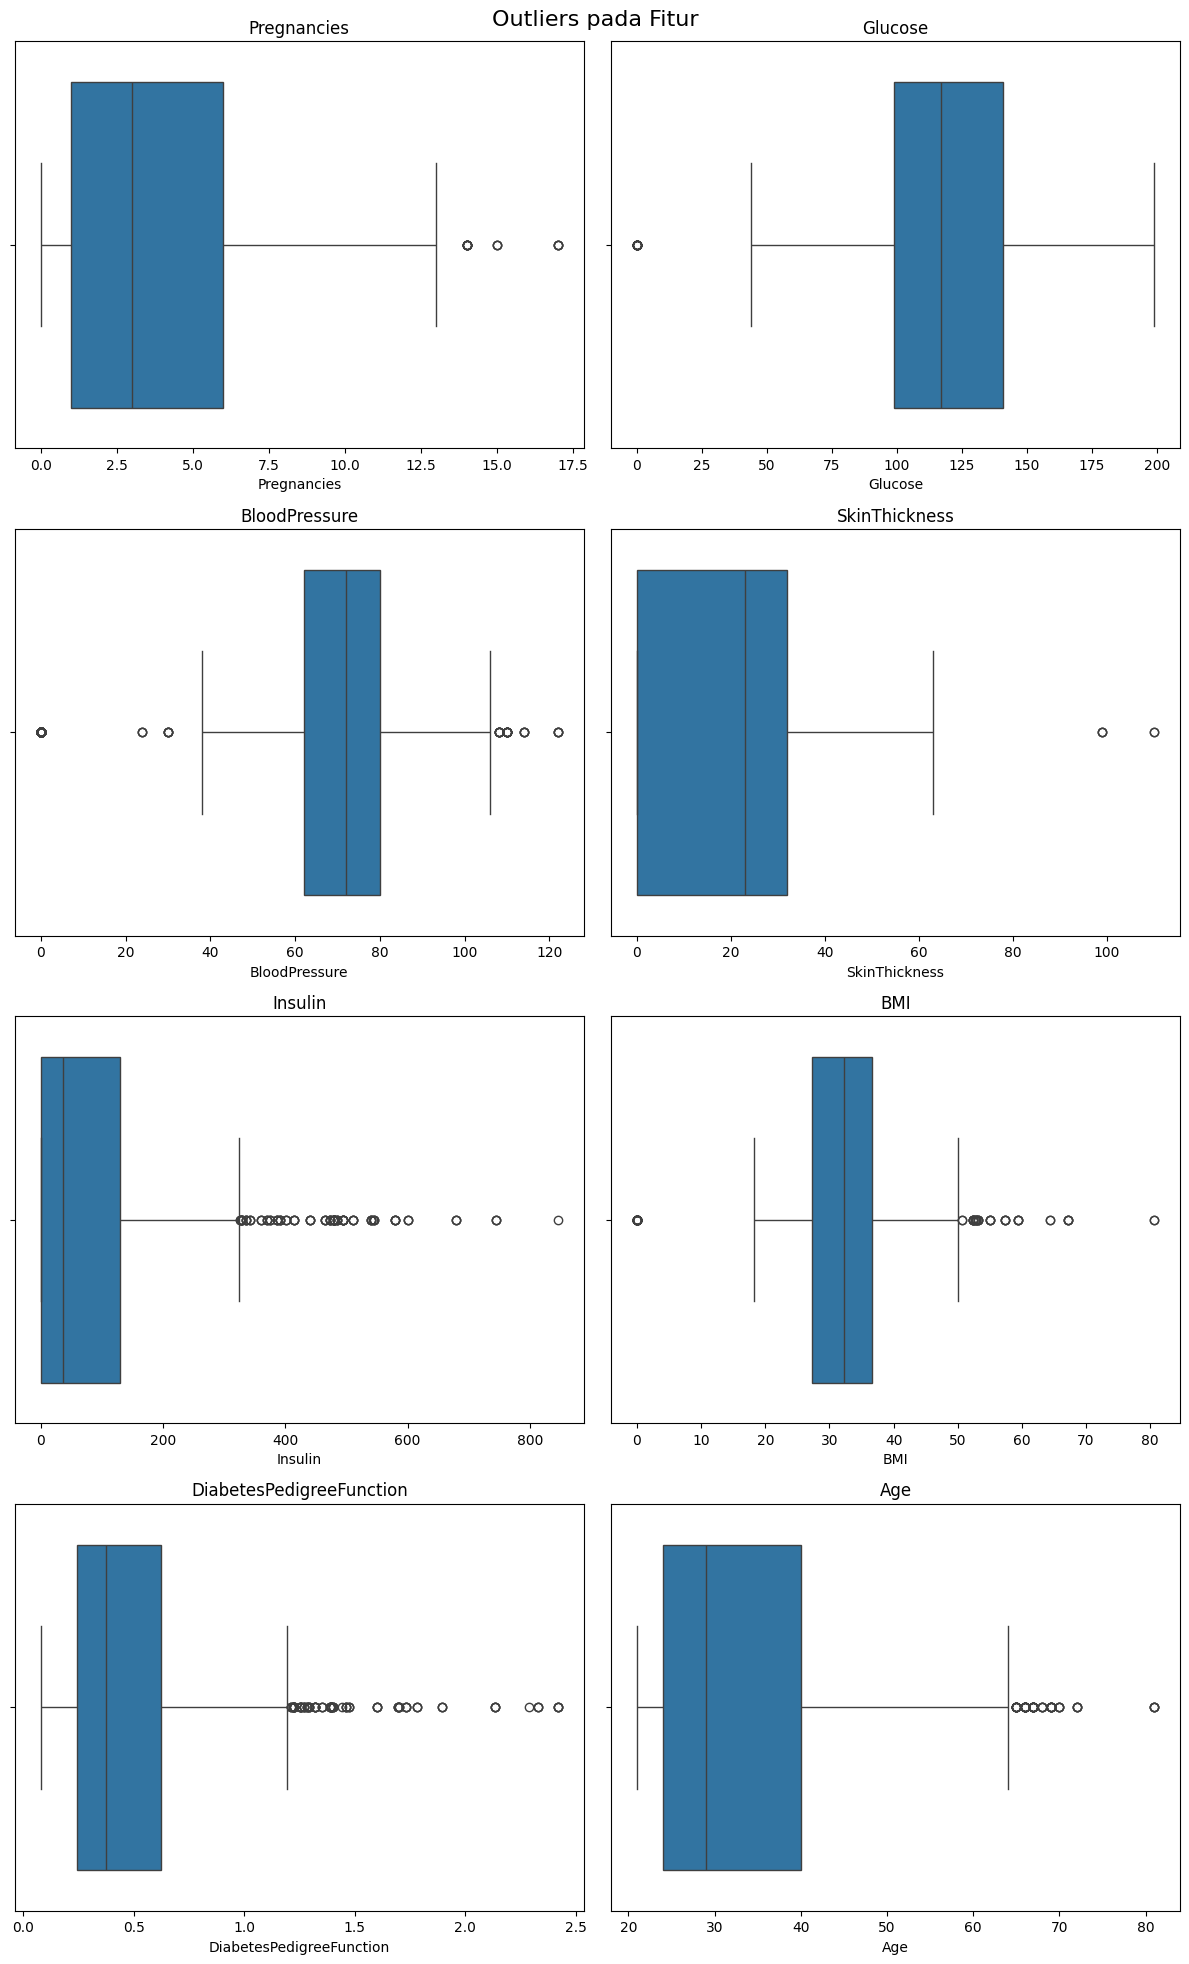

In [ ]:
num_cols = 2
num_rows = (len(features) + num_cols - 1) // num_cols

fig, axes = plt.subplots(nrows=num_rows, ncols=num_cols, figsize=(12, 5 * num_rows))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.boxplot(x=df[col], ax=axes[i])
    axes[i].set_title(f'{col}')
    axes[i].set_xlabel(col)
plt.suptitle('Outliers pada Fitur', fontsize=16)
plt.tight_layout()
plt.show()

Dapat dilihat hampir semua memiliki outlier dan ada beberapa fitur yang memiliki anomali

#### Univariate Analysis

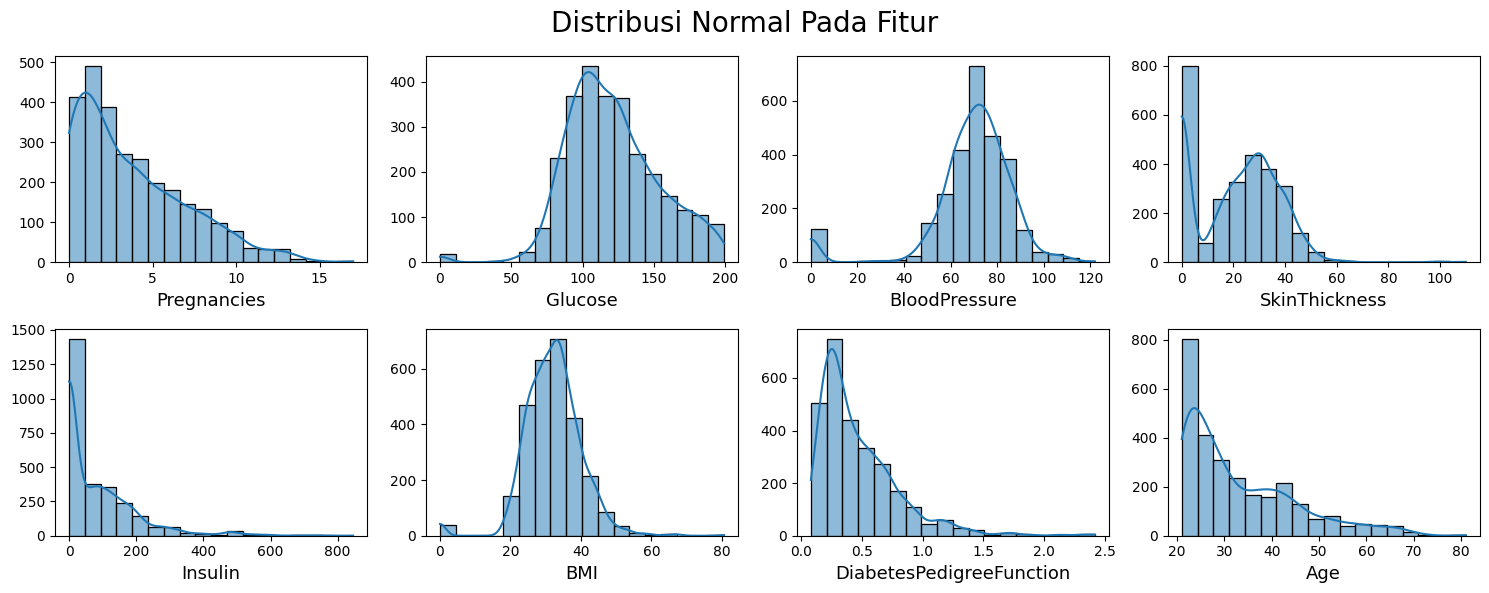

In [ ]:
# Analisis Distribusi Normal
plt.figure(figsize=(15,6))
plt.suptitle('Distribusi Normal Pada Fitur', fontsize=20)
for i, col in enumerate(features, 1):
    plt.subplot(2, 4, i)
    sns.histplot(df, x=col, kde=True, bins=18)
    plt.xlabel(col, fontsize=13)
    plt.ylabel('')

plt.tight_layout()
plt.show()

Sebagian besar fitur menunjukkan distribusi yang tidak normal. Hanya Glucose dan BloodPressure yang tampak mendekati distribusi normal, meskipun keduanya mengandung nilai outlier berupa angka 0. Sementara itu, fitur-fitur lainnya cenderung memiliki distribusi miring ke kanan (right-skewed). Nilai 0 pada fitur Glucose dan BloodPressure akan dihapus karena dianggap sebagai anomali yang tidak sesuai dengan kondisi sebenarnya.

In [ ]:
def drop_anomaly(df):
    anomaly = ['Glucose', 'BloodPressure', 'BMI']
    Q1 = df[anomaly].quantile(0.25)
    Q3 = df[anomaly].quantile(0.75)
    IQR = Q3 - Q1

    # Hanya menghilangkan bagian bawah yang bernilai 0
    min = Q1 - (IQR * 1.5)
    lower_array = np.where(df[anomaly] <= min)[0]
    df.drop(index=lower_array, inplace=True)
    return df

df = drop_anomaly(df)
df.shape

(2604, 9)

Menghapus anomali yaitu nilai 0

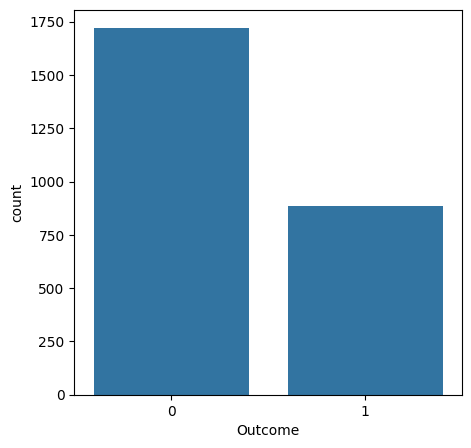

In [ ]:
plt.figure(figsize=(5,5))
sns.countplot(df, x='Outcome')
plt.show()

In [ ]:
outcome_df = df['Outcome'].value_counts().reset_index()
outcome_df.columns = ['Outcome', 'Jumlah']
outcome_df

,Outcome,Jumlah
0,0,1720
1,1,884


Data klasifikasi biner pada fitur Outcome menunjukkan ketidakseimbangan, di mana jumlah sampel dengan kategori tidak mengidap diabetes (0) hampir dua kali lebih banyak dibandingkan dengan sampel yang mengidap diabetes (1).

#### Multivariate Analysis

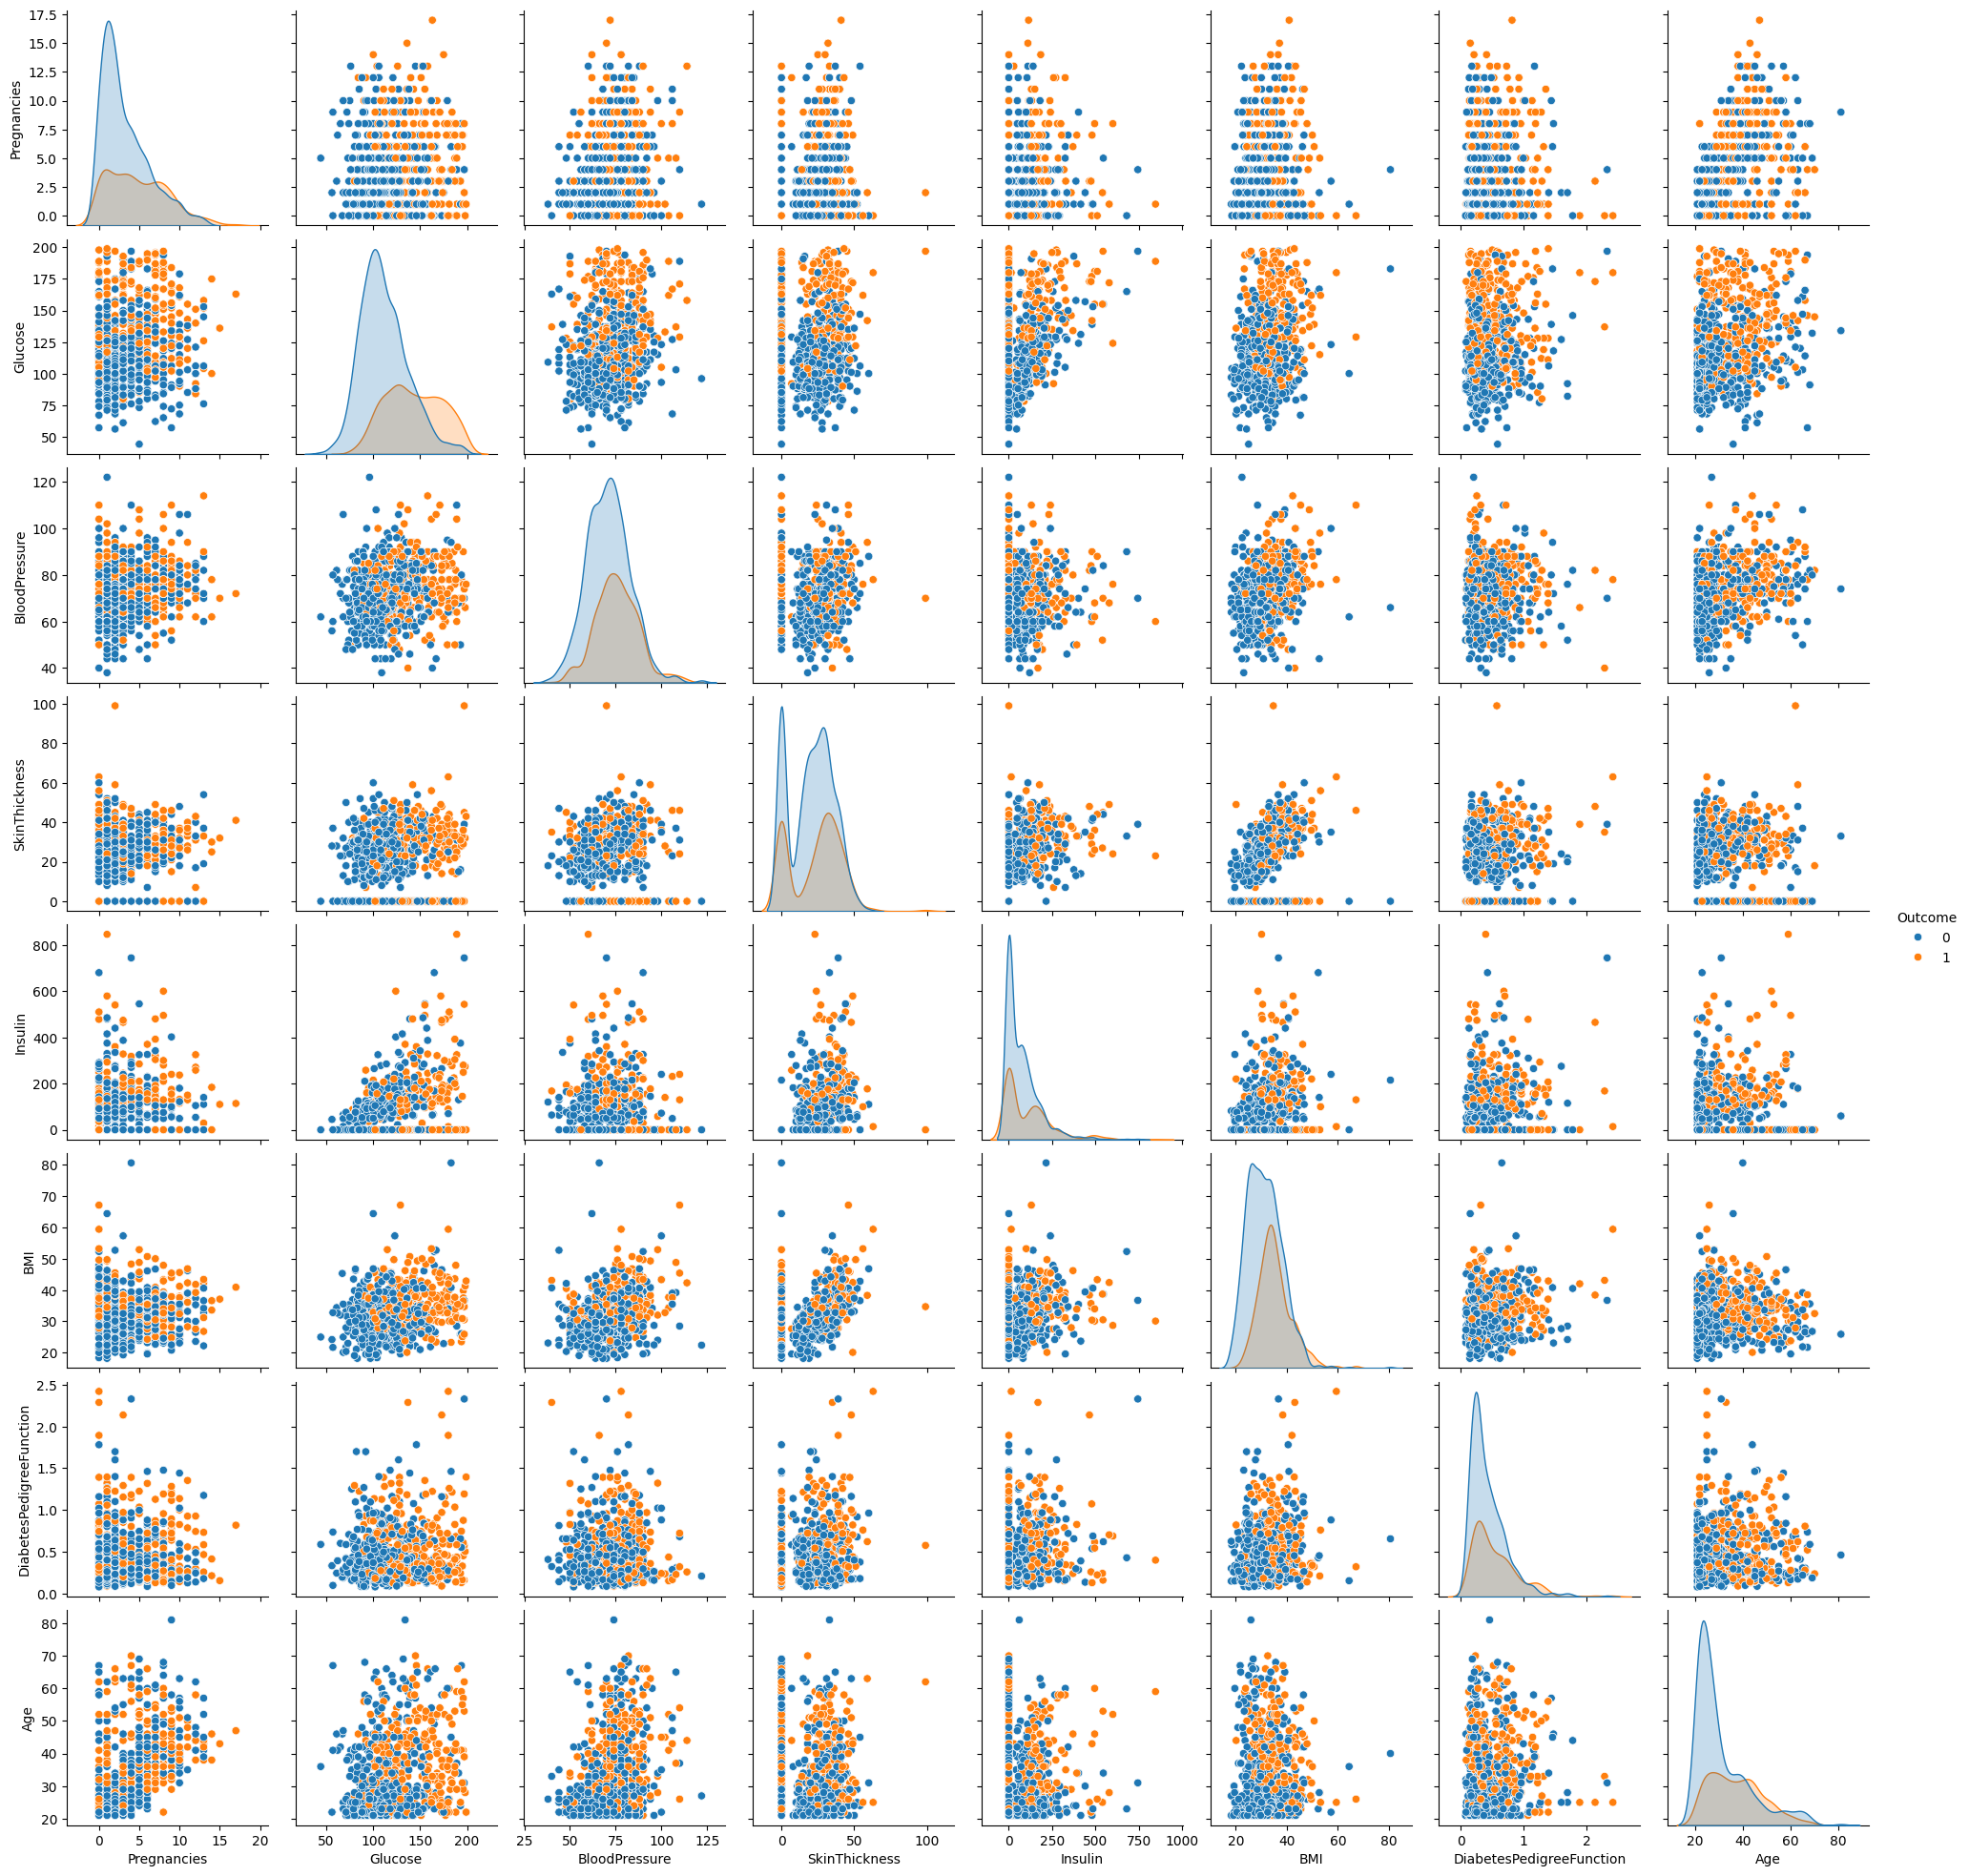

In [ ]:
sns.pairplot(df, hue='Outcome')

Pairplot tidak menunjukkan adanya informasi yang signifikan untuk mengidentifikasi hubungan antar fitur, baik yang bersifat positif maupun negatif.

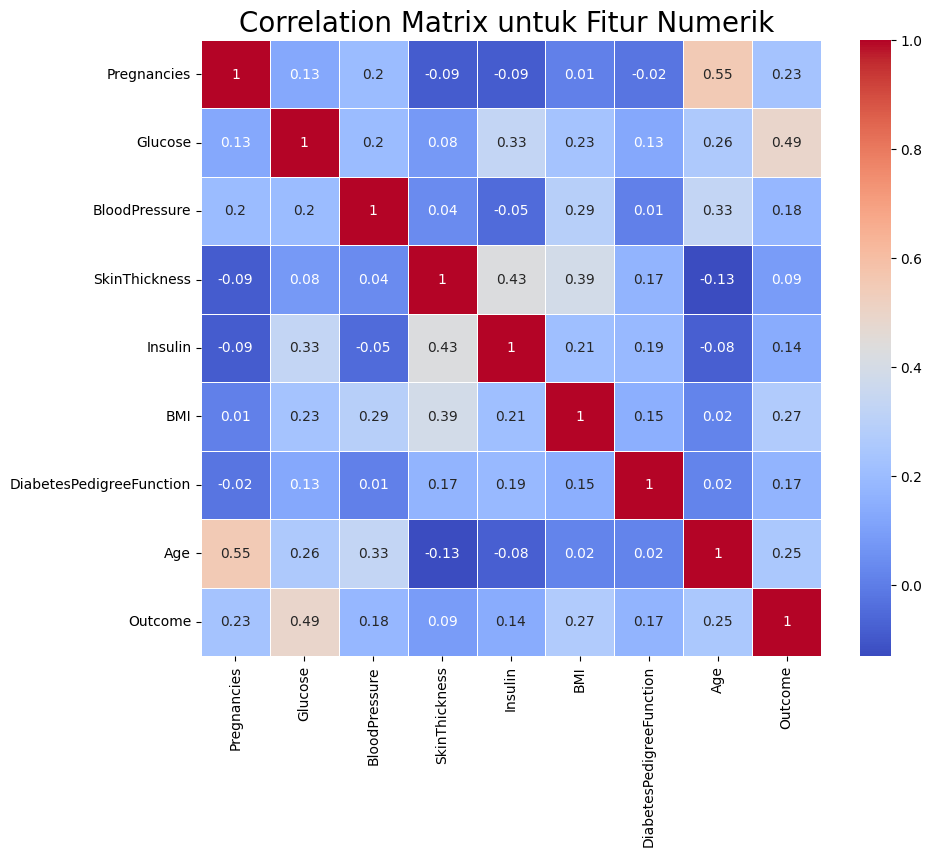

In [ ]:
plt.figure(figsize=(10, 8))
correlation_matrix = df.corr().round(2)
sns.heatmap(data=correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5, )
plt.title("Correlation Matrix untuk Fitur Numerik ", size=20);

Matriks korelasi mengindikasikan adanya hubungan antar fitur yang terdapat dalam dataset. Fitur Glucose (0,49), BMI (0,27), Age (0,25), dan Pregnancies (0,23) menunjukkan korelasi yang lebih kuat terhadap variabel Outcome, yang merupakan indikator keberadaan diabetes, dibandingkan fitur lainnya. Sementara itu, fitur BloodPressure (0,18), DiabetesPedigreeFunction (0,17), dan Insulin (0,14) juga memiliki korelasi dengan Outcome, meskipun dengan nilai yang lebih rendah. Terdapat pula beberapa pasangan fitur yang memiliki korelasi tinggi satu sama lain namun korelasinya terhadap Outcome relatif rendah, seperti antara Age dan Pregnancies (0,55), Insulin dan SkinThickness (0,43), BMI dan SkinThickness (0,39), Age dan BloodPressure (0,33), serta Glucose dan Insulin (0,33), dan lain-lain.

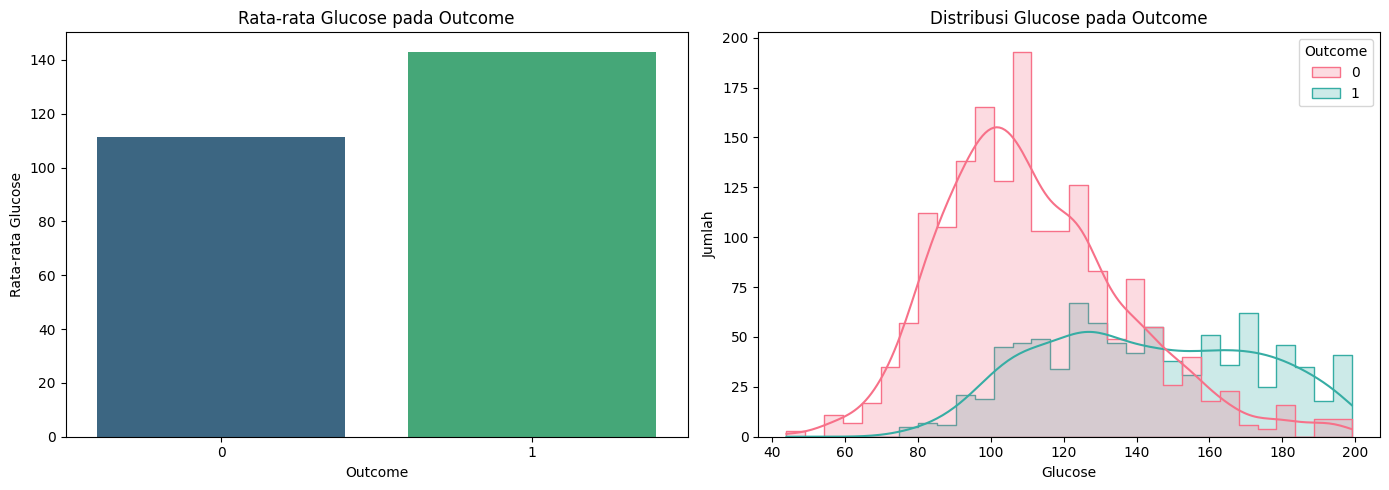

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=df, x='Outcome', y='Glucose', errorbar=None, hue='Outcome', palette='viridis', legend=False, ax=axes[0])
axes[0].set_title('Rata-rata Glucose pada Outcome')
axes[0].set_xlabel('Outcome')
axes[0].set_ylabel('Rata-rata Glucose')

sns.histplot(data=df, x='Glucose', hue='Outcome', kde=True, bins=30, palette='husl', element='step', ax=axes[1])
axes[1].set_title('Distribusi Glucose pada Outcome')
axes[1].set_xlabel('Glucose')
axes[1].set_ylabel('Jumlah')

plt.tight_layout()
plt.show()

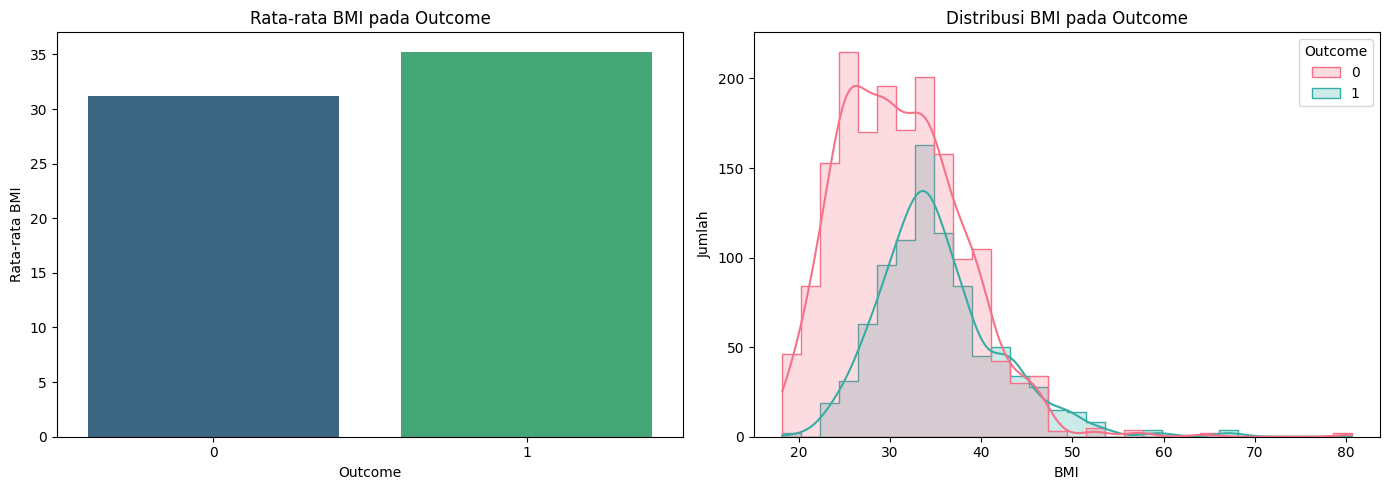

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=df, x='Outcome', y='BMI', errorbar=None, hue='Outcome', palette='viridis', legend=False, ax=axes[0])
axes[0].set_title('Rata-rata BMI pada Outcome')
axes[0].set_xlabel('Outcome')
axes[0].set_ylabel('Rata-rata BMI')

sns.histplot(data=df, x='BMI', hue='Outcome', kde=True, bins=30, palette='husl', element='step', ax=axes[1])
axes[1].set_title('Distribusi BMI pada Outcome')
axes[1].set_xlabel('BMI')
axes[1].set_ylabel('Jumlah')

plt.tight_layout()
plt.show()

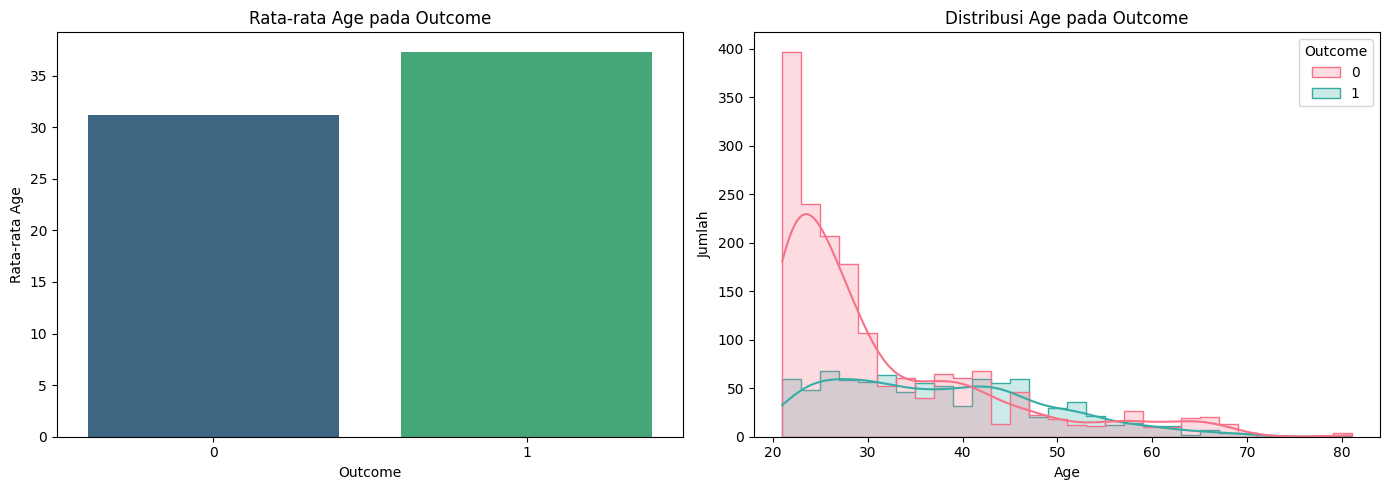

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=df, x='Outcome', y='Age', errorbar=None, hue='Outcome', palette='viridis', legend=False, ax=axes[0])
axes[0].set_title('Rata-rata Age pada Outcome')
axes[0].set_xlabel('Outcome')
axes[0].set_ylabel('Rata-rata Age')

sns.histplot(data=df, x='Age', hue='Outcome', kde=True, bins=30, palette='husl', element='step', ax=axes[1])
axes[1].set_title('Distribusi Age pada Outcome')
axes[1].set_xlabel('Age')
axes[1].set_ylabel('Jumlah')

plt.tight_layout()
plt.show()


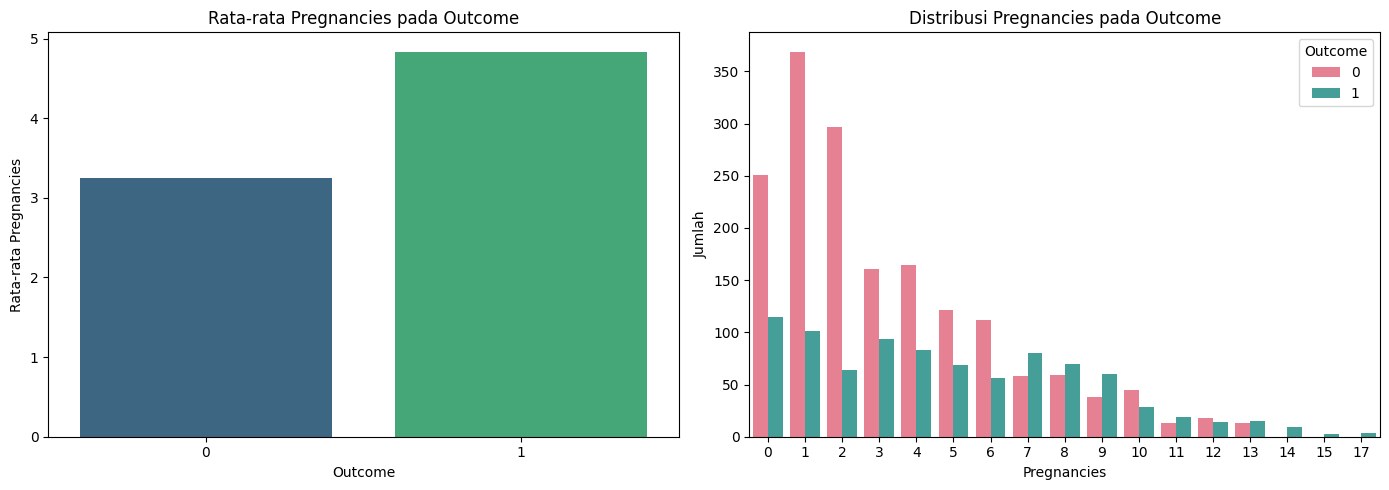

In [ ]:
# Analisis hubungan antara Pregnancies dan Outcome
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=df, x='Outcome', y='Pregnancies', errorbar=None, hue='Outcome', palette='viridis', legend=False, ax=axes[0])
axes[0].set_title('Rata-rata Pregnancies pada Outcome')
axes[0].set_xlabel('Outcome')
axes[0].set_ylabel('Rata-rata Pregnancies')

sns.countplot(data=df, x='Pregnancies', hue='Outcome', palette='husl', ax=axes[1])
axes[1].set_title('Distribusi Pregnancies pada Outcome')
axes[1].set_xlabel('Pregnancies')
axes[1].set_ylabel('Jumlah')

plt.tight_layout()
plt.show()

Pada keempat grafik, terlihat bahwa nilai rata-rata pada keempat fitur tersebut cenderung lebih tinggi pada individu yang mengidap diabetes dibandingkan dengan mereka yang tidak mengidap diabetes.

## Data Preparation

In [ ]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
# Memilih fitur dengan menyesuaikan korelasi terhadap Outcome
fix_features = ['Pregnancies', 'Glucose', 'BMI', 'Age', 'Outcome']
numerical_features = [i for i in fix_features if i != 'Outcome']
df_new = df[fix_features]
df_new.head()

,Pregnancies,Glucose,BMI,Age,Outcome
0,6,148,33.6,50,1
1,1,85,26.6,31,0
2,8,183,23.3,32,1
3,1,89,28.1,21,0
4,0,137,43.1,33,1


In [ ]:
X = df_new.drop('Outcome', axis=1)
y = df_new['Outcome']

In [ ]:
from sklearn.model_selection import train_test_split
# Membagi data menjadi 80% train dan 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=55)
print(f'Total # of sample in whole dataset: {len(X)}')
print(f'Total # of sample in train dataset: {len(X_train)}')
print(f'Total # of sample in test dataset: {len(X_test)}')

Total # of sample in whole dataset: 2604
Total # of sample in train dataset: 2083
Total # of sample in test dataset: 521


In [ ]:
from sklearn.preprocessing import StandardScaler
# Standarisasi data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
X_train

array([[-0.53033135, -2.12473773, -1.21018073, -0.96768637],
       [-1.12972376,  0.07155905, -1.55570574, -1.05406695],
       [-0.23063515,  0.03926056,  3.55518496, -0.96768637],
       ...,
       [ 0.96814967, -0.41291818,  0.47425367,  0.8463057 ],
       [-1.12972376,  0.39454387, -0.89344948, -1.05406695],
       [ 0.06906106,  0.10385753, -0.5335276 ,  1.01906685]])

## Modelling

### Logistic Regression
Logistic Regression adalah algoritma klasifikasi yang digunakan untuk memprediksi probabilitas kejadian suatu peristiwa. Model ini menggunakan fungsi sigmoid untuk memetakan input numerik menjadi nilai probabilitas antara 0 dan 1. Meskipun disebut "regression," algoritma ini digunakan untuk tugas klasifikasi biner dan dapat diperluas ke klasifikasi multikelas.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

log_reg = LogisticRegression()
log_reg.fit(X_train, y_train)
log_reg_pred = log_reg.predict(X_test)

print(classification_report(y_test, log_reg_pred))

              precision    recall  f1-score   support

           0       0.80      0.87      0.83       349
           1       0.68      0.55      0.61       172

    accuracy                           0.77       521
   macro avg       0.74      0.71      0.72       521
weighted avg       0.76      0.77      0.76       521



In [ ]:
print("Akurasi : {:.2f}".format(accuracy_score(y_test, log_reg_pred)))

Akurasi : 0.77


#### Grid Search Logistic Regression

In [ ]:
from sklearn.model_selection import GridSearchCV
# Menentukan kombinasi hyperparameter untuk diuji pada Logistic Regression
parameter_logreg = {
    'C': [0.001, 0.01, 0.1, 1, 10],
    'solver': ['liblinear', 'newton-cg', 'lbfgs', 'sag', 'saga']
}

# Melakukan pencarian grid terbaik menggunakan validasi silang
grid_lr = GridSearchCV(estimator=log_reg, param_grid=parameter_logreg,
                       cv=5, scoring='accuracy', verbose=1)
grid_lr.fit(X_train, y_train)

# Menampilkan kombinasi parameter terbaik
optimal_params = grid_lr.best_params_
print("Hyperparameter Terbaik:", optimal_params)

# Menyimpan model dengan performa terbaik dari hasil grid search
optimal_model = grid_lr.best_estimator_

# Prediksi menggunakan model terbaik
y_pred_optimal = optimal_model.predict(X_test)

# Evaluasi akurasi model terbaik
best_acc = accuracy_score(y_test, y_pred_optimal)
print(f"Akurasi Model Terbaik: {best_acc:.2f}")

Fitting 5 folds for each of 25 candidates, totalling 125 fits
Hyperparameter Terbaik: {'C': 0.01, 'solver': 'newton-cg'}
Akurasi Model Terbaik: 0.77


### KNN
KNN adalah algoritma non-parametrik yang digunakan untuk klasifikasi dan regresi. Model ini menentukan kelas atau nilai dari suatu data baru berdasarkan mayoritas kelas atau rata-rata nilai dari 'k' tetangga terdekatnya dalam ruang fitur.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
# Memilih 5 nilai K secara acak
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
knn_pred = knn.predict(X_test)

print(classification_report(y_test, knn_pred))

              precision    recall  f1-score   support

           0       0.89      0.91      0.90       349
           1       0.81      0.78      0.79       172

    accuracy                           0.87       521
   macro avg       0.85      0.84      0.85       521
weighted avg       0.86      0.87      0.87       521



In [ ]:
print("Skor Akurasi : {:.2f}".format(accuracy_score(y_test, knn_pred)))

Skor Akurasi : 0.87


#### Elbow Method

In [ ]:
from sklearn.metrics import accuracy_score
# Menghitung nilai optimal K dengan Elbow Method
error_rate = []

# Uji performa KNN untuk nilai K dari 1 sampai 7
for k in range(1, 8):
    model_knn = KNeighborsClassifier(n_neighbors=k)
    model_knn.fit(X_train, y_train)

    prediksi = model_knn.predict(X_test)
    akurasi = accuracy_score(y_test, prediksi)

    print(f"K = {k} -> Akurasi: {akurasi:.2f}")

    # Hitung error rate sebagai proporsi prediksi salah
    kesalahan = np.mean(prediksi != y_test)
    error_rate.append(kesalahan)

K = 1 -> Akurasi: 1.00
K = 2 -> Akurasi: 0.97
K = 3 -> Akurasi: 0.94
K = 4 -> Akurasi: 0.89
K = 5 -> Akurasi: 0.87
K = 6 -> Akurasi: 0.83
K = 7 -> Akurasi: 0.83


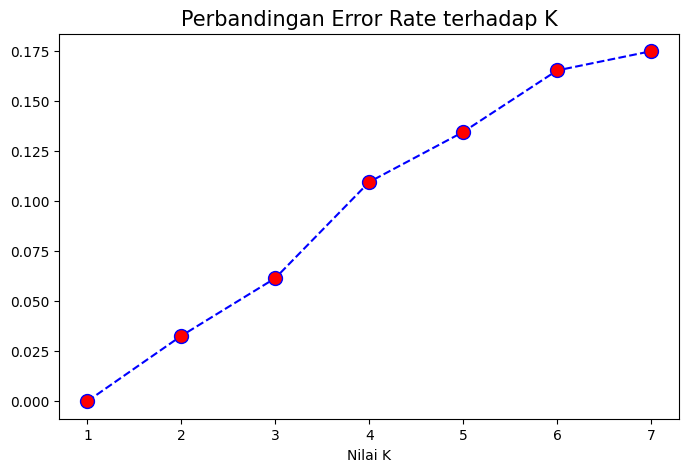

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(range(1, 8), error_rate, color='blue', linestyle='dashed', marker='o', markerfacecolor='red', markersize=10)
plt.title('Perbandingan Error Rate terhadap K', fontsize=15)
plt.xlabel('Nilai K')
plt.ylabel('')
plt.show()

In [ ]:
# Memilih error rate terkecil
print("Minimum error:",min(error_rate)," terdapat pada K = ",error_rate.index(min(error_rate))+1)

Minimum error: 0.0  terdapat pada K =  1


In [ ]:
knn = KNeighborsClassifier(n_neighbors=2)
knn.fit(X_train, y_train)
knn_pred = knn.predict(X_test)

print(classification_report(y_test, knn_pred))

              precision    recall  f1-score   support

           0       0.95      1.00      0.98       349
           1       1.00      0.90      0.95       172

    accuracy                           0.97       521
   macro avg       0.98      0.95      0.96       521
weighted avg       0.97      0.97      0.97       521



In [ ]:
print("Skor Akurasi : {:.2f}".format(accuracy_score(y_test, knn_pred)))

Skor Akurasi : 0.97


### Support Vector Machine
SVM adalah algoritma klasifikasi yang mencari hyperplane optimal yang memisahkan kelas-kelas dalam ruang fitur. Dengan menggunakan kernel trick, SVM dapat menangani data yang tidak dapat dipisahkan secara linear dengan memetakan data ke ruang berdimensi lebih tinggi.

In [ ]:
from sklearn.svm import SVC
svm = SVC()
svm.fit(X_train, y_train)
svm_pred = svm.predict(X_test)

print(classification_report(y_test, svm_pred))

              precision    recall  f1-score   support

           0       0.82      0.90      0.86       349
           1       0.75      0.60      0.67       172

    accuracy                           0.80       521
   macro avg       0.79      0.75      0.76       521
weighted avg       0.80      0.80      0.80       521



In [ ]:
print("Skor Akurasi : {:.2f}".format(accuracy_score(y_test, svm_pred)))

Skor Akurasi : 0.80


#### Grid Search SVM

In [ ]:
svm_param_grid = {'C': [0.1, 1, 10, 100, 1000],
                  'gamma': [1, 0.1, 0.01, 0.001, 0.0001],
                  'kernel': ['rbf']
}
svm_grid = GridSearchCV(SVC(), svm_param_grid, cv=5, scoring='accuracy', verbose = 1)
svm_grid.fit(X_train, y_train)

best_svm_params = svm_grid.best_params_
print("Hyperparameter Terbaik:", best_svm_params)

best_model_svm = svm_grid.best_estimator_

y_pred_optimal = best_model_svm.predict(X_test)

best_acc_svm = accuracy_score(y_test, y_pred_optimal)
print(f"Akurasi Model Terbaik: {best_acc_svm:.2f}")

Fitting 5 folds for each of 25 candidates, totalling 125 fits
Hyperparameter Terbaik: {'C': 1000, 'gamma': 1, 'kernel': 'rbf'}
Akurasi Model Terbaik: 0.98


In [ ]:
svm_pred = best_model_svm.predict(X_test)

print(classification_report(y_test, svm_pred))

              precision    recall  f1-score   support

           0       0.99      0.97      0.98       349
           1       0.95      0.99      0.97       172

    accuracy                           0.98       521
   macro avg       0.97      0.98      0.98       521
weighted avg       0.98      0.98      0.98       521



## Evaluasi Model

### Confusion Matrix

In [ ]:
models_pred = {
    'Logistic Regression': log_reg_pred,
    'KNN': knn_pred,
    'SVM': svm_pred
}

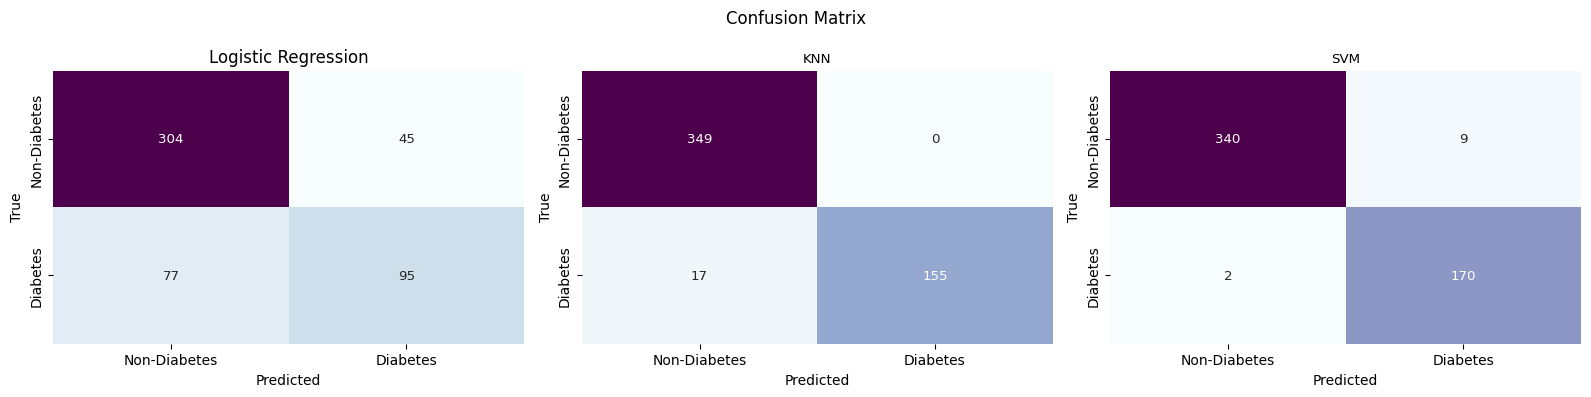

In [ ]:
fig, axes = plt.subplots(1, len(models_pred), figsize=(16, 4))
fig.suptitle('Confusion Matrix')

for idx, (model_name, model_pred) in enumerate(models_pred.items()):
    cm = confusion_matrix(y_test, model_pred)
    ax = axes[idx]
    ax.set_title(model_name)
    sns.set(font_scale=0.8)

    sns.heatmap(cm, annot=True, cmap='BuPu', cbar=False, fmt='d',
                xticklabels=['Non-Diabetes', 'Diabetes'],
                yticklabels=['Non-Diabetes', 'Diabetes'],
                ax=ax)

    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')

plt.tight_layout()
plt.show()

- SVM menunjukkan performa tertinggi dengan akurasi 97%, didukung oleh nilai FN (False Negative) yang sangat rendah (hanya 2 kasus), yang berarti model ini sangat baik dalam mendeteksi pasien diabetes.

- KNN menghasilkan recall tinggi (0.90) dan presisi sempurna (1.00), namun tampak overfitting karena tidak memprediksi satu pun kasus negatif sebagai positif.

- Logistic Regression memberikan performa moderat dan seimbang, namun FN yang cukup tinggi (77 kasus) mengindikasikan banyak pasien diabetes tidak terdeteksi.

### Tabel Evaluasi

In [ ]:
# Daftar model yang digunakan dan prediksi masing-masing
model_names = ['Logistic Regression', 'K-Nearest Neighbor', 'SVM']
model_predictions = [log_reg_pred, knn_pred, svm_pred]

# List untuk menyimpan hasil evaluasi
evaluation_results = []

# Iterasi setiap model dan prediksinya untuk menghitung metrik evaluasi
for name, prediction in zip(model_names, model_predictions):
    acc = round(accuracy_score(y_test, prediction) * 100, 2)
    prec = round(precision_score(y_test, prediction) * 100, 2)
    rec = round(recall_score(y_test, prediction) * 100, 2)
    f1s = round(f1_score(y_test, prediction) * 100, 2)

    evaluation_results.append([acc, prec, rec, f1s])

# Menyusun hasil evaluasi dalam DataFrame
evaluation_df = pd.DataFrame(evaluation_results,
                             columns=['Accuracy (%)', 'Precision (%)', 'Recall (%)', 'F1 Score (%)'],
                             index=model_names)

evaluation_df

,Accuracy (%),Precision (%),Recall (%),F1 Score (%)
Logistic Regression,76.58,67.86,55.23,60.90
K-Nearest Neighbor,96.74,100.00,90.12,94.80
SVM,97.89,94.97,98.84,96.87


Hasil menunjukkan bahwa KNN dan SVM menjadi yang terbaik dengan performa dengan Accuracy 96.7% dan F1-score 94.8% untuk KNN dan Accuracy 97.8% dan F1-score 96.8% untuk SVM. Sementara itu, Regresi Logistik memberikan hasil yang kurang memuaskan, dengan Accuracy 76.5% dan F1-score 60.9%.